In [1]:
!pip install GEOparse

#GEO Dataset GSE106817


In [2]:
## GEO Dataset GSE106817
import GEOparse
import os
import pandas as pd
import warnings
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
# Setup working directory and suppress warning
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("GEOparse").setLevel(logging.CRITICAL)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
# -----------------------------
# =========================================================
# Config
# =========================================================

GEO_ID = "GSE106817"

base_path = "/content/GEO_data/"
output_dir = "/content/drive/MyDrive/geo_mirna_project/processed"

os.makedirs(base_path, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# =========================================================
# Step 1 — Download GEO dataset
# =========================================================

print("Downloading dataset...")

gse = GEOparse.get_GEO(
    geo=GEO_ID,
    destdir=base_path,
    silent=True
)

print("Download complete")
print("--------------------------------------------------")

# =========================================================
# Step 2 — Platform information
# =========================================================

platform_rows = []

print("Platform IDs:")
print(list(gse.gpls.keys()))

for gpl_id, gpl in gse.gpls.items():

    title = gpl.metadata.get("title", ["NA"])[0]
    technology = gpl.metadata.get("technology", ["NA"])[0]
    manufacturer = gpl.metadata.get("manufacturer", ["NA"])[0]

    platform_text = f"{title} {technology} {manufacturer}".lower()

    is_mirna_platform = any(k in platform_text for k in [
        "mirna",
        "microrna",
        "mirbase",
        "3d-gene",
        "taqman",
        "ncrna"
    ])

    platform_rows.append({
        "GSE": GEO_ID,
        "GPL": gpl_id,
        "title": title,
        "technology": technology,
        "manufacturer": manufacturer,
        "is_miRNA_platform": is_mirna_platform
    })

    print("\nPlatform:", gpl_id)
    print("Title:", title)
    print("Technology:", technology)
    print("Manufacturer:", manufacturer)
    print("miRNA platform:", is_mirna_platform)

platform_df = pd.DataFrame(platform_rows)

platform_df.to_csv(
    os.path.join(output_dir, f"{GEO_ID}_platform_QC.csv"),
    index=False
)

print("--------------------------------------------------")

# -----------------------------
# Phenotype data
# -----------------------------
pheno_data = pd.DataFrame([gsm.metadata for gsm in gse.gsms.values()])
pheno_data["title"] = pheno_data["title"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["geo_accession"] = pheno_data["geo_accession"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["type"] = pheno_data["title"].str.extract(r"\s(.+)")
pheno_data["type"] = pheno_data.apply(
    lambda row: row["title"].rsplit(" ", 1)[0] if pd.isna(row["type"]) or any(char.isdigit() for char in str(row["type"])) else row["type"],
    axis=1
)

# Display the raw pheno_data for context
print("First 5 rows of Phenotype Data:")
display(pheno_data.head())
print("-------------------------------------------------------")

pheno_data.to_csv(f"{GEO_ID}_Phenotype_Data.csv", sep=',', index=False)
print(f"Phenotype data exported to {GEO_ID}_Phenotype_Data.csv")

pheno_data_filtered = pheno_data[["type", "geo_accession"]]
pheno_data_filtered.set_index("geo_accession", inplace=True)
pheno_data_filtered.index.name = None

# Summary of Disease Types
disease_counts = pheno_data_filtered["type"].value_counts()
disease_percentages = (disease_counts / disease_counts.sum()) * 100
summary = pd.DataFrame({
    "Count": disease_counts,
    "Percentage (%)": disease_percentages.round(2)
})
print(f"Phenotype Summary for {GEO_ID}")
print(summary)
print("-------------------------------------------------------")

# -----------------------------
# Filter for Target Diseases
# -----------------------------
def assign_label(x):
    if x == "Breast Cancer":
        return 1
    elif x == "non-Cancer":
        return 0
    else:
        return None

pheno_data_filtered["label"] = pheno_data_filtered["type"].apply(assign_label)
pheno_data_filtered = pheno_data_filtered.dropna(subset=["label"])
print("Filtered Samples with numeric labels")
print(pheno_data_filtered)
print("-------------------------------------------------------")
# -----------------------------
# Gene Annotation
# -----------------------------
gene_anno = gse.gpls[list(gse.gpls.keys())[0]].table[["ID", "miRNA_ID_LIST"]].dropna()
gene_anno.set_index("ID", inplace=True)
gene_anno.index.name = None
print("Gene Annotation")
print(gene_anno.iloc[:5])
print("-------------------------------------------------------")

# -----------------------------
# Expression Data
# -----------------------------
expression_data = gse.pivot_samples('VALUE').T
expression_data.index.name = None
expression_data = expression_data.dropna(axis=0, how='any')  # Drop samples with missing values

print("-------------------------------------------------------")

expression_pheno_data = pd.merge(pheno_data_filtered, expression_data, left_index=True, right_index=True).copy()
df = expression_pheno_data.rename(columns={"type": "type"})

print("-------------------------------------------------------")
# -----------------------------
# Làm việc trực tiếp với dữ liệu raw (df)
# -----------------------------

# Gán nhãn số cho cột type (ép kiểu int để bỏ .0)
df["type"] = df["label"].astype(int)

# Đổi tên cột probe ID thành miRNA_ID_LIST
anno_dict = gene_anno["miRNA_ID_LIST"].to_dict()
df = df.rename(columns=anno_dict)

# Sắp xếp lại cột: chỉ giữ 'type' trước, rồi đến các gene (bỏ 'label')
cols = ['type'] + [col for col in df.columns if col not in ['type', 'label']]
df = df[cols]

# Display result
print("Raw Expression Data")
print(df.iloc[:5, :5])
print(df.shape)
# Save to file

print("-------------------------------------------------------")
print("Disease Type Counts:")
print(df["type"].value_counts())

print("-------------------------------------------------------")
# Duplicate Checks

dup_index = df.index.duplicated().sum()
print("Number of duplicate samples by geo_accession:", dup_index)

dup_rows = df.duplicated().sum()
print("Number of duplicate samples by full profile:", dup_rows)

if dup_rows > 0:
    print("List of duplicate samples:")
    print(df[df.duplicated(keep=False)])

df.to_csv(f"{GEO_ID}_Raw_Full_Probe.csv", sep=',', index=True)


print("\nFull Phenotype Data:")
display(pheno_data)

Download complete
--------------------------------------------------
Platform IDs:
['GPL21263']

Platform: GPL21263
Title: 3D-Gene Human miRNA V21_1.0.0
Technology: spotted oligonucleotide
Manufacturer: Toray Industries,Inc.
miRNA platform: True
--------------------------------------------------
First 5 rows of Phenotype Data:


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_name,contact_email,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,Breast Cancer BC1281,GSM2850709,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
1,Breast Cancer BC1286,GSM2850710,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
2,Breast Cancer BC1288,GSM2850711,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
3,Breast Cancer BC1292,GSM2850712,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
4,Breast Cancer BC1293,GSM2850713,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]


-------------------------------------------------------
Phenotype data exported to GSE106817_Phenotype_Data.csv
Phenotype Summary for GSE106817
                          Count  Percentage (%)
type                                           
non-Cancer                 2759           68.19
Ovarian Cancer              320            7.91
Gastric Cancer              115            2.84
Colorectal Cancer           115            2.84
Breast Cancer               115            2.84
Sarcoma                     115            2.84
Lung Cancer                 115            2.84
Pancreatic Cancer           115            2.84
Esophageal Cancer            88            2.17
Hepatocellular Carcinoma     81            2.00
Borderline Ovarian Tumor     66            1.63
Benign Ovarian Disease       29            0.72
OV_others                    13            0.32
-------------------------------------------------------
Filtered Samples with numeric labels
                     type  label
GSM2850709

,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_name,contact_email,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,Breast Cancer BC1281,GSM2850709,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
1,Breast Cancer BC1286,GSM2850710,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
2,Breast Cancer BC1288,GSM2850711,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
3,Breast Cancer BC1292,GSM2850712,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
4,Breast Cancer BC1293,GSM2850713,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Breast Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4041,Sarcoma SA0971,GSM2854750,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
4042,Sarcoma SA0972,GSM2854751,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
4043,Sarcoma SA0992,GSM2854752,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]
4044,Sarcoma SA0995,GSM2854753,[Public on Oct 23 2018],[Nov 13 2017],[Oct 23 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM285...,[GSE106817],[2565]


Performing PCA...
PCA plot saved to: /content/drive/MyDrive/geo_mirna_project/processed/GSE106817_PCA_plot.png


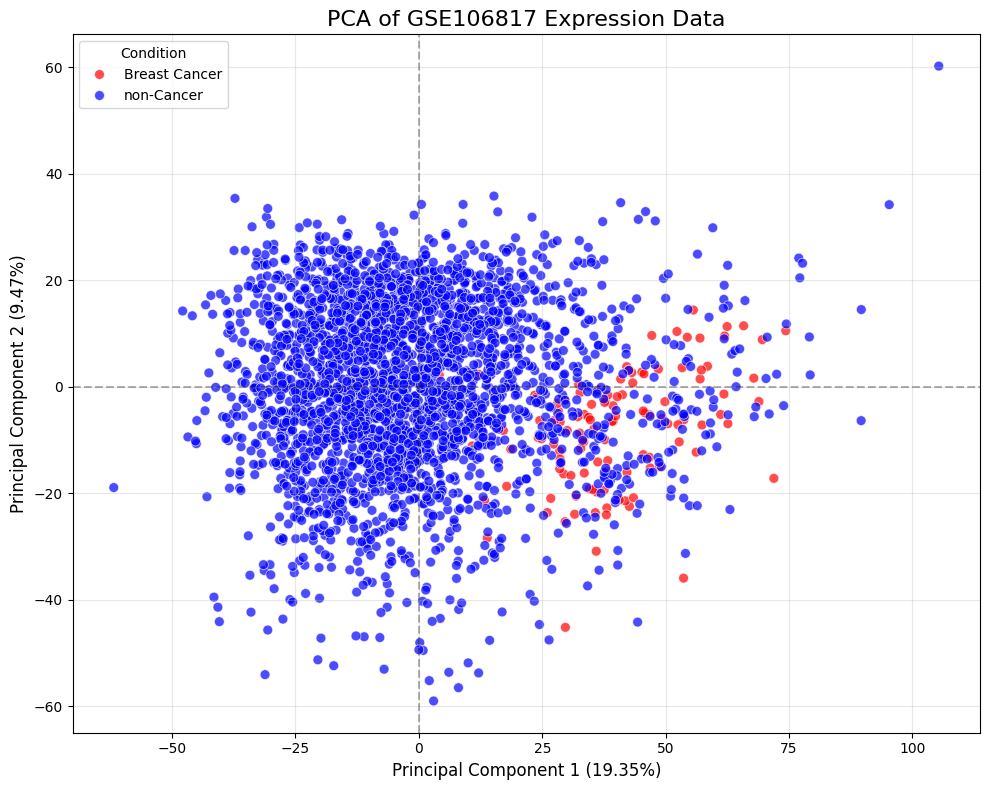

In [3]:
# =========================================================
# PCA and Visualization
# =========================================================
from sklearn.decomposition import PCA

print("Performing PCA...")

# 1. Separate features (expression data) and target labels
X = df.drop(columns=['type'])
y = df['type']

# 2. Standardize the data (mean=0, variance=1)
# PCA is highly sensitive to the scale of the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Perform PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Get the explained variance percentage for the axes
explained_variance = pca.explained_variance_ratio_ * 100

# 4. Create a DataFrame for visualization
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'], index=df.index)
pca_df['type'] = y

# Map numeric types back to string labels for the plot legend
pca_df['Disease Type'] = pca_df['type'].map({0: 'non-Cancer', 1: 'Breast Cancer'})

# 5. Visualize with Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Disease Type',
    palette={'non-Cancer': 'blue', 'Breast Cancer': 'red'},
    data=pca_df,
    alpha=0.7,
    s=50
)

# Formatting the plot
plt.title(f'PCA of {GEO_ID} Expression Data', fontsize=16)
plt.xlabel(f'Principal Component 1 ({explained_variance[0]:.2f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({explained_variance[1]:.2f}%)', fontsize=12)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.3)
plt.legend(title='Condition')
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the plot
pca_plot_path = os.path.join(output_dir, f"{GEO_ID}_PCA_plot.png")
plt.savefig(pca_plot_path, dpi=300)
print(f"PCA plot saved to: {pca_plot_path}")

plt.show()

#GEO Dataset GSE113486


In [4]:
## GEO Dataset GSE113486
import GEOparse
import os
import pandas as pd
import warnings
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
# Setup working directory and suppress warning
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("GEOparse").setLevel(logging.CRITICAL)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
# -----------------------------
# =========================================================
# Config
# =========================================================

GEO_ID = "GSE113486"

base_path = "/content/GEO_data/"
output_dir = "/content/drive/MyDrive/geo_mirna_project/processed"

os.makedirs(base_path, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# =========================================================
# Step 1 — Download GEO dataset
# =========================================================

print("Downloading dataset...")

gse = GEOparse.get_GEO(
    geo=GEO_ID,
    destdir=base_path,
    silent=True
)

print("Download complete")
print("--------------------------------------------------")

# =========================================================
# Step 2 — Platform information
# =========================================================

platform_rows = []

print("Platform IDs:")
print(list(gse.gpls.keys()))

for gpl_id, gpl in gse.gpls.items():

    title = gpl.metadata.get("title", ["NA"])[0]
    technology = gpl.metadata.get("technology", ["NA"])[0]
    manufacturer = gpl.metadata.get("manufacturer", ["NA"])[0]

    platform_text = f"{title} {technology} {manufacturer}".lower()

    is_mirna_platform = any(k in platform_text for k in [
        "mirna",
        "microrna",
        "mirbase",
        "3d-gene",
        "taqman",
        "ncrna"
    ])

    platform_rows.append({
        "GSE": GEO_ID,
        "GPL": gpl_id,
        "title": title,
        "technology": technology,
        "manufacturer": manufacturer,
        "is_miRNA_platform": is_mirna_platform
    })

    print("\nPlatform:", gpl_id)
    print("Title:", title)
    print("Technology:", technology)
    print("Manufacturer:", manufacturer)
    print("miRNA platform:", is_mirna_platform)

platform_df = pd.DataFrame(platform_rows)

platform_df.to_csv(
    os.path.join(output_dir, f"{GEO_ID}_platform_QC.csv"),
    index=False
)

print("--------------------------------------------------")

# -----------------------------
# Phenotype data
# -----------------------------
pheno_data = pd.DataFrame([gsm.metadata for gsm in gse.gsms.values()])
pheno_data["title"] = pheno_data["title"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["geo_accession"] = pheno_data["geo_accession"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["type"] = pheno_data["title"].str.extract(r"\s(.+)")
pheno_data["type"] = pheno_data.apply(
    lambda row: row["title"].rsplit(" ", 1)[0] if pd.isna(row["type"]) or any(char.isdigit() for char in str(row["type"])) else row["type"],
    axis=1
)

# Display the raw pheno_data for context
print("First 5 rows of Phenotype Data:")
display(pheno_data.head())
print("-------------------------------------------------------")

pheno_data.to_csv(f"{GEO_ID}_Phenotype_Data.csv", sep=',', index=False)
print(f"Phenotype data exported to {GEO_ID}_Phenotype_Data.csv")

pheno_data_filtered = pheno_data[["type", "geo_accession"]]
pheno_data_filtered.set_index("geo_accession", inplace=True)
pheno_data_filtered.index.name = None

# Summary of Disease Types
disease_counts = pheno_data_filtered["type"].value_counts()
disease_percentages = (disease_counts / disease_counts.sum()) * 100
summary = pd.DataFrame({
    "Count": disease_counts,
    "Percentage (%)": disease_percentages.round(2)
})
print(f"Phenotype Summary for {GEO_ID}")
print(summary)
print("-------------------------------------------------------")

# -----------------------------
# Filter for Target Diseases
# -----------------------------
def assign_label(x):
    if x == "Breast Cancer":
        return 1
    elif x == "Non-cancer control":
        return 0
    else:
        return None

pheno_data_filtered["label"] = pheno_data_filtered["type"].apply(assign_label)
pheno_data_filtered = pheno_data_filtered.dropna(subset=["label"])
print("Filtered Samples with numeric labels")
print(pheno_data_filtered)
print("-------------------------------------------------------")
# -----------------------------
# Gene Annotation
# -----------------------------
gene_anno = gse.gpls[list(gse.gpls.keys())[0]].table[["ID", "miRNA_ID_LIST"]].dropna()
gene_anno.set_index("ID", inplace=True)
gene_anno.index.name = None
print("Gene Annotation")
print(gene_anno.iloc[:5])
print("-------------------------------------------------------")

# -----------------------------
# Expression Data
# -----------------------------
expression_data = gse.pivot_samples('VALUE').T
expression_data.index.name = None
expression_data = expression_data.dropna(axis=0, how='any')  # Drop samples with missing values

print("-------------------------------------------------------")

expression_pheno_data = pd.merge(pheno_data_filtered, expression_data, left_index=True, right_index=True).copy()
df = expression_pheno_data.rename(columns={"type": "type"})

print("-------------------------------------------------------")
# -----------------------------
# Làm việc trực tiếp với dữ liệu raw (df)
# -----------------------------

# Gán nhãn số cho cột type (ép kiểu int để bỏ .0)
df["type"] = df["label"].astype(int)

# Đổi tên cột probe ID thành miRNA_ID_LIST
anno_dict = gene_anno["miRNA_ID_LIST"].to_dict()
df = df.rename(columns=anno_dict)

# Sắp xếp lại cột: chỉ giữ 'type' trước, rồi đến các gene (bỏ 'label')
cols = ['type'] + [col for col in df.columns if col not in ['type', 'label']]
df = df[cols]

# Display result
print("Raw Expression Data")
print(df.iloc[:5, :5])
print(df.shape)
# Save to file

print("-------------------------------------------------------")
print("Disease Type Counts:")
print(df["type"].value_counts())

print("-------------------------------------------------------")
# Duplicate Checks

dup_index = df.index.duplicated().sum()
print("Number of duplicate samples by geo_accession:", dup_index)

dup_rows = df.duplicated().sum()
print("Number of duplicate samples by full profile:", dup_rows)

if dup_rows > 0:
    print("List of duplicate samples:")
    print(df[df.duplicated(keep=False)])

df.to_csv(f"{GEO_ID}_Raw_Full_Probe.csv", sep=',', index=True)


print("\nFull Phenotype Data:")
display(pheno_data)

Download complete
--------------------------------------------------
Platform IDs:
['GPL21263']

Platform: GPL21263
Title: 3D-Gene Human miRNA V21_1.0.0
Technology: spotted oligonucleotide
Manufacturer: Toray Industries,Inc.
miRNA platform: True
--------------------------------------------------
First 5 rows of Phenotype Data:


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_name,contact_email,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,Bladder Cancer [BL0001],GSM3106847,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
1,Bladder Cancer [BL0003],GSM3106848,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
2,Bladder Cancer [BL0004],GSM3106849,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
3,Bladder Cancer [BL0007],GSM3106850,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,"[GSE113486, GSE113740]",[2565]
4,Bladder Cancer [BL0008],GSM3106851,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]


-------------------------------------------------------
Phenotype data exported to GSE113486_Phenotype_Data.csv
Phenotype Summary for GSE113486
                          Count  Percentage (%)
type                                           
Bladder Cancer              392           40.33
Non-cancer control          100           10.29
Breast Cancer                40            4.12
Biliary Tract Cancer         40            4.12
Colorectal Cancer            40            4.12
Esophageal Cancer            40            4.12
Gastric Cancer               40            4.12
Glioma                       40            4.12
Hepatocellular Carcinoma     40            4.12
Lung Cancer                  40            4.12
Ovarian Cancer               40            4.12
Pancreatic Cancer            40            4.12
Prostate Cancer              40            4.12
Sarcoma                      40            4.12
-------------------------------------------------------
Filtered Samples with numeric la

,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_name,contact_email,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,Bladder Cancer [BL0001],GSM3106847,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
1,Bladder Cancer [BL0003],GSM3106848,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
2,Bladder Cancer [BL0004],GSM3106849,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
3,Bladder Cancer [BL0007],GSM3106850,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,"[GSE113486, GSE113740]",[2565]
4,Bladder Cancer [BL0008],GSM3106851,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Bladder Cancer,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
967,Sarcoma [SA0922],GSM3107823,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,"[GSE113486, GSE113740]",[2565]
968,Sarcoma [SA0923],GSM3107824,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
969,Sarcoma [SA0937],GSM3107825,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]
970,Sarcoma [SA0939],GSM3107826,[Public on Nov 06 2018],[Apr 20 2018],[Nov 06 2018],Sarcoma,[1],[Serum],[Homo sapiens],[9606],...,"[Satoko,,Takizawa]",[satoko.takizawa.f3@mail.toray],[Toray industries inc],[kamakurashi],[Kanagawa],[248-8555],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM310...,[GSE113486],[2565]


Performing PCA...
PCA plot saved to: /content/drive/MyDrive/geo_mirna_project/processed/GSE113486_PCA_plot.png


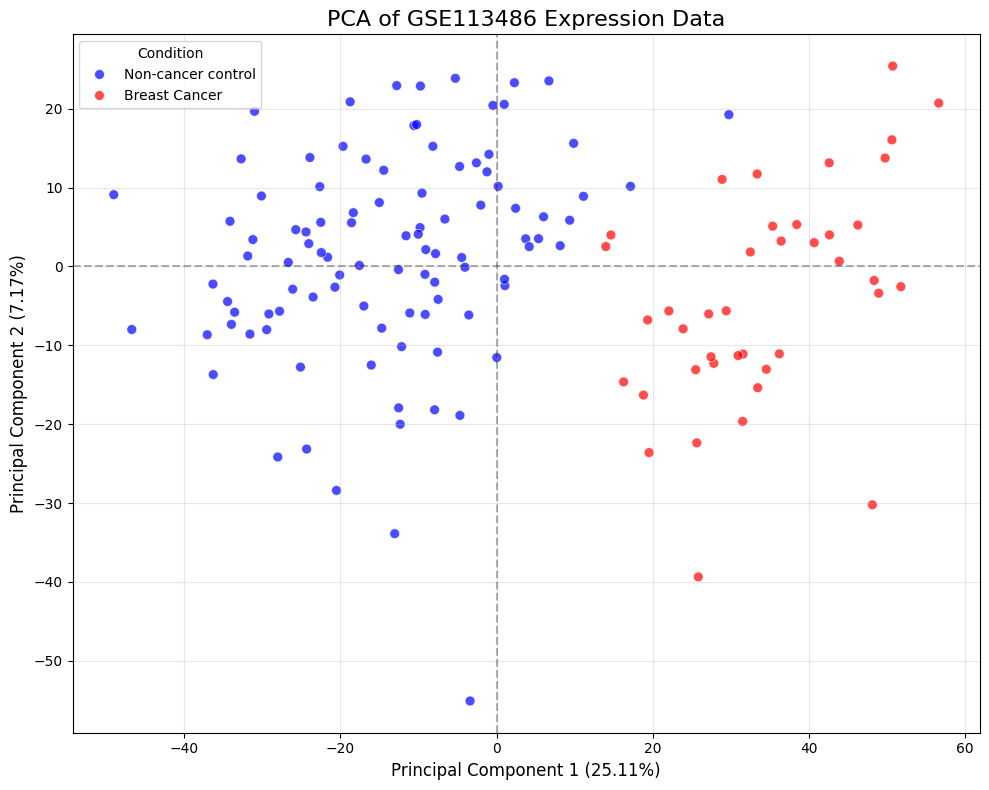

In [5]:
# =========================================================
# PCA and Visualization
# =========================================================
from sklearn.decomposition import PCA

print("Performing PCA...")

# 1. Separate features (expression data) and target labels
X = df.drop(columns=['type'])
y = df['type']

# 2. Standardize the data (mean=0, variance=1)
# PCA is highly sensitive to the scale of the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Perform PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Get the explained variance percentage for the axes
explained_variance = pca.explained_variance_ratio_ * 100

# 4. Create a DataFrame for visualization
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'], index=df.index)
pca_df['type'] = y

# Map numeric types back to string labels for the plot legend
pca_df['Disease Type'] = pca_df['type'].map({0: 'Non-cancer control', 1: 'Breast Cancer'})

# 5. Visualize with Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Disease Type',
    palette={'Non-cancer control': 'blue', 'Breast Cancer': 'red'},
    data=pca_df,
    alpha=0.7,
    s=50
)

# Formatting the plot
plt.title(f'PCA of {GEO_ID} Expression Data', fontsize=16)
plt.xlabel(f'Principal Component 1 ({explained_variance[0]:.2f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({explained_variance[1]:.2f}%)', fontsize=12)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.3)
plt.legend(title='Condition')
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the plot
pca_plot_path = os.path.join(output_dir, f"{GEO_ID}_PCA_plot.png")
plt.savefig(pca_plot_path, dpi=300)
print(f"PCA plot saved to: {pca_plot_path}")

plt.show()

#GEO Dataset GSE73002

In [6]:
## GEO Dataset GSE73002
import GEOparse
import os
import pandas as pd
import warnings
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
# Setup working directory and suppress warning
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("GEOparse").setLevel(logging.CRITICAL)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
# -----------------------------
# =========================================================
# Config
# =========================================================

GEO_ID = "GSE73002"

base_path = "/content/GEO_data/"
output_dir = "/content/drive/MyDrive/geo_mirna_project/processed"

os.makedirs(base_path, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# =========================================================
# Step 1 — Download GEO dataset
# =========================================================

print("Downloading dataset...")

gse = GEOparse.get_GEO(
    geo=GEO_ID,
    destdir=base_path,
    silent=True
)

print("Download complete")
print("--------------------------------------------------")

# =========================================================
# Step 2 — Platform information
# =========================================================

platform_rows = []

print("Platform IDs:")
print(list(gse.gpls.keys()))

for gpl_id, gpl in gse.gpls.items():

    title = gpl.metadata.get("title", ["NA"])[0]
    technology = gpl.metadata.get("technology", ["NA"])[0]
    manufacturer = gpl.metadata.get("manufacturer", ["NA"])[0]

    platform_text = f"{title} {technology} {manufacturer}".lower()

    is_mirna_platform = any(k in platform_text for k in [
        "mirna",
        "microrna",
        "mirbase",
        "3d-gene",
        "taqman",
        "ncrna"
    ])

    platform_rows.append({
        "GSE": GEO_ID,
        "GPL": gpl_id,
        "title": title,
        "technology": technology,
        "manufacturer": manufacturer,
        "is_miRNA_platform": is_mirna_platform
    })

    print("\nPlatform:", gpl_id)
    print("Title:", title)
    print("Technology:", technology)
    print("Manufacturer:", manufacturer)
    print("miRNA platform:", is_mirna_platform)

platform_df = pd.DataFrame(platform_rows)

platform_df.to_csv(
    os.path.join(output_dir, f"{GEO_ID}_platform_QC.csv"),
    index=False
)

print("--------------------------------------------------")

# -----------------------------
# Phenotype data
# -----------------------------
pheno_data = pd.DataFrame([gsm.metadata for gsm in gse.gsms.values()])
pheno_data["title"] = pheno_data["title"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["geo_accession"] = pheno_data["geo_accession"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["type"] = pheno_data["title"].str.extract(r"\s(.+)")
pheno_data["type"] = pheno_data.apply(
    lambda row: row["title"].rsplit(" ", 1)[0] if pd.isna(row["type"]) or any(char.isdigit() for char in str(row["type"])) else row["type"],
    axis=1
)

# Display the raw pheno_data for context
print("First 5 rows of Phenotype Data:")
display(pheno_data.head())
print("-------------------------------------------------------")

pheno_data.to_csv(f"{GEO_ID}_Phenotype_Data.csv", sep=',', index=False)
print(f"Phenotype data exported to {GEO_ID}_Phenotype_Data.csv")

pheno_data_filtered = pheno_data[["type", "geo_accession"]]
pheno_data_filtered.set_index("geo_accession", inplace=True)
pheno_data_filtered.index.name = None

# Summary of Disease Types
disease_counts = pheno_data_filtered["type"].value_counts()
disease_percentages = (disease_counts / disease_counts.sum()) * 100
summary = pd.DataFrame({
    "Count": disease_counts,
    "Percentage (%)": disease_percentages.round(2)
})
print(f"Phenotype Summary for {GEO_ID}")
print(summary)
print("-------------------------------------------------------")

# -----------------------------
# Filter for Target Diseases
# -----------------------------
def assign_label(x):
    if x == "TS_B:" or x == "TR_B:":
        return 1
    elif x == "TR_N:" or x == "TS_N:":
        return 0
    else:
        return None

pheno_data_filtered["label"] = pheno_data_filtered["type"].apply(assign_label)
pheno_data_filtered = pheno_data_filtered.dropna(subset=["label"])
print("Filtered Samples with numeric labels")
print(pheno_data_filtered)
print("-------------------------------------------------------")
# -----------------------------
# Gene Annotation
# -----------------------------
gene_anno = gse.gpls[list(gse.gpls.keys())[0]].table[["ID", "miRNA_ID_LIST"]].dropna()
gene_anno.set_index("ID", inplace=True)
gene_anno.index.name = None
print("Gene Annotation")
print(gene_anno.iloc[:5])
print("-------------------------------------------------------")

# -----------------------------
# Expression Data
# -----------------------------
expression_data = gse.pivot_samples('VALUE').T
expression_data.index.name = None
expression_data = expression_data.dropna(axis=1, how='any')  # Drop samples with missing values

print("-------------------------------------------------------")

expression_pheno_data = pd.merge(pheno_data_filtered, expression_data, left_index=True, right_index=True).copy()
df = expression_pheno_data.rename(columns={"type": "type"})

print("-------------------------------------------------------")
# -----------------------------
# Làm việc trực tiếp với dữ liệu raw (df)
# -----------------------------

# Gán nhãn số cho cột type (ép kiểu int để bỏ .0)
df["type"] = df["label"].astype(int)

# Đổi tên cột probe ID thành miRNA_ID_LIST
anno_dict = gene_anno["miRNA_ID_LIST"].to_dict()
df = df.rename(columns=anno_dict)

# Sắp xếp lại cột: chỉ giữ 'type' trước, rồi đến các gene (bỏ 'label')
cols = ['type'] + [col for col in df.columns if col not in ['type', 'label']]
df = df[cols]

# Display result
print("Raw Expression Data")
print(df.iloc[:5, :5])
print(df.shape)
# Save to file

print("-------------------------------------------------------")
print("Disease Type Counts:")
print(df["type"].value_counts())

print("-------------------------------------------------------")
# Duplicate Checks

dup_index = df.index.duplicated().sum()
print("Number of duplicate samples by geo_accession:", dup_index)

dup_rows = df.duplicated().sum()
print("Number of duplicate samples by full profile:", dup_rows)

if dup_rows > 0:
    print("List of duplicate samples:")
    print(df[df.duplicated(keep=False)])

df.to_csv(f"{GEO_ID}_Raw_Full_Probe.csv", sep=',', index=True)


print("\nFull Phenotype Data:")
display(pheno_data)

Download complete
--------------------------------------------------
Platform IDs:
['GPL18941']

Platform: GPL18941
Title: 3D-Gene Human miRNA V20_1.0.0
Technology: spotted oligonucleotide
Manufacturer: Toray Industries, Inc.
miRNA platform: True
--------------------------------------------------
First 5 rows of Phenotype Data:


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_phone,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,TS_B: BC0004,GSM1876422,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
1,TS_B: BC0005,GSM1876423,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
2,TS_B: BC0006,GSM1876424,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
3,TS_B: BC0007,GSM1876425,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
4,TS_B: BC0008,GSM1876426,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]


-------------------------------------------------------
Phenotype data exported to GSE73002_Phenotype_Data.csv
Phenotype Summary for GSE73002
        Count  Percentage (%)
type                         
TR_N:    1343           32.65
TS_N:    1343           32.65
TS_B:    1206           29.32
TR_PR:     93            2.26
TR_B:      74            1.80
TS_G:      54            1.31
-------------------------------------------------------
Filtered Samples with numeric labels
             type  label
GSM1876422  TS_B:    1.0
GSM1876423  TS_B:    1.0
GSM1876424  TS_B:    1.0
GSM1876425  TS_B:    1.0
GSM1876426  TS_B:    1.0
...           ...    ...
GSM1880435  TS_B:    1.0
GSM1880436  TS_B:    1.0
GSM1880437  TS_B:    1.0
GSM1880438  TS_B:    1.0
GSM1880439  TS_B:    1.0

[3966 rows x 2 columns]
-------------------------------------------------------
Gene Annotation
              miRNA_ID_LIST
MIMAT0000062  hsa-let-7a-5p
MIMAT0000063  hsa-let-7b-5p
MIMAT0000064  hsa-let-7c-5p
MIMAT0000065  hs

,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_phone,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,TS_B: BC0004,GSM1876422,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
1,TS_B: BC0005,GSM1876423,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
2,TS_B: BC0006,GSM1876424,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
3,TS_B: BC0007,GSM1876425,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
4,TS_B: BC0008,GSM1876426,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TS_B:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM187...,[GSE73002],[2540]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4108,TR_PR: PR79,GSM1880530,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TR_PR:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM188...,[GSE73002],[2540]
4109,TR_PR: PR86,GSM1880531,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TR_PR:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM188...,[GSE73002],[2540]
4110,TR_PR: PR88,GSM1880532,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TR_PR:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM188...,[GSE73002],[2540]
4111,TR_PR: PR89,GSM1880533,[Public on Jan 21 2016],[Sep 14 2015],[Jan 21 2016],TR_PR:,[1],[serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM188...,[GSE73002],[2540]


Performing PCA...
PCA plot saved to: /content/drive/MyDrive/geo_mirna_project/processed/GSE73002_PCA_plot.png


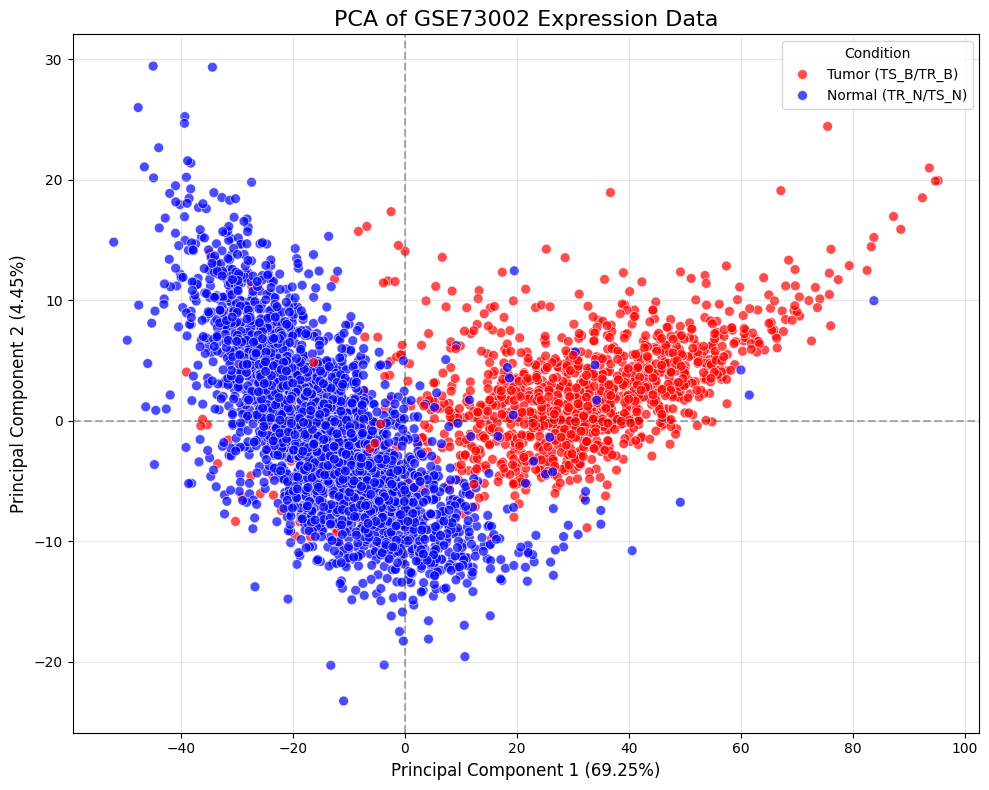

In [7]:
# =========================================================
# PCA and Visualization
# =========================================================
from sklearn.decomposition import PCA

print("Performing PCA...")

# 1. Separate features (expression data) and target labels
X = df.drop(columns=['type'])
y = df['type']

# 2. Standardize the data (mean=0, variance=1)
# PCA is highly sensitive to the scale of the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Perform PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Get the explained variance percentage for the axes
explained_variance = pca.explained_variance_ratio_ * 100

# 4. Create a DataFrame for visualization
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'], index=df.index)
pca_df['type'] = y

# Fix the mapping: Map numeric types back to string labels for the plot legend.
# Since 1 groups both TS_B and TR_B, and 0 groups TR_N and TS_N, we label them as combined groups.
pca_df['Disease Type'] = pca_df['type'].map({
    0: 'Normal (TR_N/TS_N)',
    1: 'Tumor (TS_B/TR_B)'
})

# 5. Visualize with Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Disease Type',
    palette={'Normal (TR_N/TS_N)': 'blue', 'Tumor (TS_B/TR_B)': 'red'},
    data=pca_df,
    alpha=0.7,
    s=50
)

# Formatting the plot
plt.title(f'PCA of {GEO_ID} Expression Data', fontsize=16)
plt.xlabel(f'Principal Component 1 ({explained_variance[0]:.2f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({explained_variance[1]:.2f}%)', fontsize=12)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.3)
plt.legend(title='Condition')
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the plot
pca_plot_path = os.path.join(output_dir, f"{GEO_ID}_PCA_plot.png")
plt.savefig(pca_plot_path, dpi=300)
print(f"PCA plot saved to: {pca_plot_path}")

plt.show()

#GEO Dataset GSE211692


In [8]:
## GEO Dataset GSE211692
import GEOparse
import os
import pandas as pd
import warnings
import logging
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
# Setup working directory and suppress warning
warnings.filterwarnings("ignore", category=SyntaxWarning)
logging.getLogger("GEOparse").setLevel(logging.CRITICAL)
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
# -----------------------------
# =========================================================
# Config
# =========================================================

GEO_ID = "GSE211692"

base_path = "/content/GEO_data/"
output_dir = "/content/drive/MyDrive/geo_mirna_project/processed"

os.makedirs(base_path, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# =========================================================
# Step 1 — Download GEO dataset
# =========================================================

print("Downloading dataset...")

gse = GEOparse.get_GEO(
    geo=GEO_ID,
    destdir=base_path,
    silent=True
)

print("Download complete")
print("--------------------------------------------------")

# =========================================================
# Step 2 — Platform information
# =========================================================

platform_rows = []

print("Platform IDs:")
print(list(gse.gpls.keys()))

for gpl_id, gpl in gse.gpls.items():

    title = gpl.metadata.get("title", ["NA"])[0]
    technology = gpl.metadata.get("technology", ["NA"])[0]
    manufacturer = gpl.metadata.get("manufacturer", ["NA"])[0]

    platform_text = f"{title} {technology} {manufacturer}".lower()

    is_mirna_platform = any(k in platform_text for k in [
        "mirna",
        "microrna",
        "mirbase",
        "3d-gene",
        "taqman",
        "ncrna"
    ])

    platform_rows.append({
        "GSE": GEO_ID,
        "GPL": gpl_id,
        "title": title,
        "technology": technology,
        "manufacturer": manufacturer,
        "is_miRNA_platform": is_mirna_platform
    })

    print("\nPlatform:", gpl_id)
    print("Title:", title)
    print("Technology:", technology)
    print("Manufacturer:", manufacturer)
    print("miRNA platform:", is_mirna_platform)

platform_df = pd.DataFrame(platform_rows)

platform_df.to_csv(
    os.path.join(output_dir, f"{GEO_ID}_platform_QC.csv"),
    index=False
)

print("--------------------------------------------------")
# -----------------------------
# Phenotype data
# -----------------------------
pheno_data = pd.DataFrame([gsm.metadata for gsm in gse.gsms.values()])
pheno_data["title"] = pheno_data["title"].apply(lambda x: x[0] if isinstance(x, list) else x)
pheno_data["geo_accession"] = pheno_data["geo_accession"].apply(lambda x: x[0] if isinstance(x, list) else x)
# Titles look like "BC0010", "XB0996", "M0731" -> leading letters are the disease-type code
pheno_data["type"] = pheno_data["title"].str.extract(r"^([A-Za-z]+)")

# Display the raw pheno_data for context
print("First 5 rows of Phenotype Data:")
display(pheno_data.head())
print("-------------------------------------------------------")

pheno_data.to_csv(f"{GEO_ID}_Phenotype_Data.csv", sep=',', index=False)
print(f"Phenotype data exported to {GEO_ID}_Phenotype_Data.csv")

# Keep 'title' too - it's the sample key actually used as columns in the expression matrix
pheno_data_filtered = pheno_data[["title", "type", "geo_accession"]].copy()
pheno_data_filtered.set_index("geo_accession", inplace=True)
pheno_data_filtered.index.name = None

# Summary of Disease Types
disease_counts = pheno_data_filtered["type"].value_counts()
disease_percentages = (disease_counts / disease_counts.sum()) * 100
summary = pd.DataFrame({
    "Count": disease_counts,
    "Percentage (%)": disease_percentages.round(2)
})
print(f"Phenotype Summary for {GEO_ID}")
print(summary)
print("-------------------------------------------------------")
# -----------------------------
# Filter for Target Diseases
# -----------------------------
def assign_label(x):
    # Ensure x is a string and check for prefixes
    val = str(x).upper()
    if val.startswith("BC"):
        return 1
    elif val.startswith("M"):
        return 0
    else:
        return None

pheno_data_filtered["label"] = pheno_data_filtered["type"].apply(assign_label)
pheno_data_filtered = pheno_data_filtered.dropna(subset=["label"])

print("Filtered Samples with numeric labels:")
print(pheno_data_filtered.head())

print("-------------------------------------------------------")


Download complete
--------------------------------------------------
Platform IDs:
['GPL21263']

Platform: GPL21263
Title: 3D-Gene Human miRNA V21_1.0.0
Technology: spotted oligonucleotide
Manufacturer: Toray Industries,Inc.
miRNA platform: True
--------------------------------------------------
First 5 rows of Phenotype Data:


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_phone,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,BC0010,GSM6483171,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
1,BC0011,GSM6483172,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
2,BC0016,GSM6483173,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
3,BC0025,GSM6483174,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
4,BC0033,GSM6483175,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]


-------------------------------------------------------
Phenotype data exported to GSE211692_Phenotype_Data.csv
Phenotype Summary for GSE211692
      Count  Percentage (%)
type                       
NB     2703           16.70
LK     1699           10.49
CC     1596            9.86
GC     1418            8.76
PR     1257            7.76
XB      992            6.13
XA      980            6.05
M       857            5.29
PC      851            5.26
BC      706            4.36
SA      612            3.78
EC      566            3.50
OV      428            2.64
BT      402            2.48
BL      399            2.46
HC      348            2.15
GL      265            1.64
CHC     111            0.69
-------------------------------------------------------
Filtered Samples with numeric labels:
             title type  label
GSM6483171  BC0010   BC    1.0
GSM6483172  BC0011   BC    1.0
GSM6483173  BC0016   BC    1.0
GSM6483174  BC0025   BC    1.0
GSM6483175  BC0033   BC    1.0
----------------

In [9]:
# -----------------------------
# Filter for Target Diseases
# -----------------------------
def assign_label(x):
    # Ensure x is a string and check for prefixes
    val = str(x).upper()
    if val.startswith("BC"):
        return 1
    elif val.startswith("M"):
        return 0
    else:
        return None

pheno_data_filtered["label"] = pheno_data_filtered["type"].apply(assign_label)
pheno_data_filtered = pheno_data_filtered.dropna(subset=["label"])

print("Filtered Samples with numeric labels:")
print(pheno_data_filtered.head())

print("-------------------------------------------------------")
# -----------------------------
# Gene Annotation
# -----------------------------
gene_anno = gse.gpls[list(gse.gpls.keys())[0]].table[["ID", "miRNA_ID_LIST"]].dropna()
gene_anno.set_index("ID", inplace=True)
gene_anno.index.name = None
print("Gene Annotation")
print(gene_anno.iloc[:5])
print("-------------------------------------------------------")

Filtered Samples with numeric labels:
             title type  label
GSM6483171  BC0010   BC      1
GSM6483172  BC0011   BC      1
GSM6483173  BC0016   BC      1
GSM6483174  BC0025   BC      1
GSM6483175  BC0033   BC      1
-------------------------------------------------------
Gene Annotation
              miRNA_ID_LIST
MIMAT0000062  hsa-let-7a-5p
MIMAT0000063  hsa-let-7b-5p
MIMAT0000064  hsa-let-7c-5p
MIMAT0000065  hsa-let-7d-5p
MIMAT0000066  hsa-let-7e-5p
-------------------------------------------------------


In [11]:
import pandas as pd
import os
import urllib.request
import urllib.error

# 1. Định nghĩa hàm tải file
def download_file(url, filepath):
    print(f"Đang tải {url} xuống {filepath}...")
    try:
        urllib.request.urlretrieve(url, filepath)
        print("Tải file thành công!")
    except urllib.error.URLError as e:
        print(f"Lỗi khi tải file: {e}")
        raise e

# (Đảm bảo bạn cũng đã định nghĩa hàm geo_ftp_root nếu nó chưa có sẵn)
# def geo_ftp_root(geo_id): ...

# -----------------------------
# Expression Data
# local matrix file -> URL found in the soft file's series metadata -> direct download
# -----------------------------
matrix_filename = f"{GEO_ID}_processed_data_matrix.txt.gz"
matrix_path = os.path.join(base_path, matrix_filename)

if os.path.exists(matrix_path):
    print(f"Loading expression matrix from local file: {matrix_path}")
else:
    print(f"{matrix_filename} not found locally - looking up its URL in the series soft-file metadata...")
    suppl_files = gse.metadata.get("supplementary_file", [])
    matrix_url = next((u for u in suppl_files if "matrix" in u.lower() and u.lower().endswith(".gz")), None)
    if matrix_url is None:
        # Series metadata didn't list it - fall back to GEO's conventional naming pattern
        matrix_url = f"{geo_ftp_root(GEO_ID)}/suppl/{matrix_filename}"

    # Lúc này hàm download_file đã tồn tại
    download_file(matrix_url, matrix_path)

expression_data = pd.read_csv(matrix_path, sep='\t', comment='!', index_col=0)

# Transpose so samples are rows and probes/genes are columns
expression_data = expression_data.T
expression_data.index.name = None
expression_data = expression_data.dropna(axis=0, how='any') # Drop samples with missing values

print(f"Expression matrix shape (samples x probes): {expression_data.shape}")
print("-------------------------------------------------------")

GSE211692_processed_data_matrix.txt.gz not found locally - looking up its URL in the series soft-file metadata...
Đang tải ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE211nnn/GSE211692/suppl/GSE211692_processed_data_matrix.txt.gz xuống /content/GEO_data/GSE211692_processed_data_matrix.txt.gz...
Tải file thành công!
Expression matrix shape (samples x probes): (16190, 2565)
-------------------------------------------------------


In [12]:
# -----------------------------
# Merge phenotype + expression data
# -----------------------------
expression_pheno_data = pd.merge(
    pheno_data_filtered.reset_index().rename(columns={"index": "geo_accession"}),
    expression_data,
    left_on="title",
    right_index=True,
).set_index("geo_accession")
expression_pheno_data.index.name = None
df = expression_pheno_data.copy()
print(f"Merged {df.shape[0]} samples with {expression_data.shape[1]} probes")
print("-------------------------------------------------------")
# -----------------------------

# -----------------------------
# Làm việc trực tiếp với dữ liệu raw (df)
# -----------------------------

# Gán nhãn số cho cột type (ép kiểu int để bỏ .0)
df["type"] = df["label"].astype(int)

# Đổi tên cột probe ID thành miRNA_ID_LIST
anno_dict = gene_anno["miRNA_ID_LIST"].to_dict()
df = df.rename(columns=anno_dict)

# Sắp xếp lại cột: chỉ giữ 'type' trước, rồi đến các gene (bỏ 'label', 'title')
cols = ['type'] + [col for col in df.columns if col not in ['type', 'label', 'title']]
df = df[cols]

# Display result
print("Raw Expression Data")
print(df.iloc[:5, :5])
print(df.shape)
# Save to file

print("-------------------------------------------------------")
print("Disease Type Counts:")
print(df["type"].value_counts())

print("-------------------------------------------------------")
# Duplicate Checks

dup_index = df.index.duplicated().sum()
print("Number of duplicate samples by geo_accession:", dup_index)

dup_rows = df.duplicated().sum()
print("Number of duplicate samples by full profile:", dup_rows)

if dup_rows > 0:
    print("List of duplicate samples:")
    print(df[df.duplicated(keep=False)])

df.to_csv(f"{GEO_ID}_Raw_Full_Probe.csv", sep=',', index=True)
print(f"Saved {len(df)} samples to {GEO_ID}_Raw_Full_Probe.csv")

print("\nFull Phenotype Data:")
display(pheno_data)

Merged 1563 samples with 2565 probes
-------------------------------------------------------
Raw Expression Data
            type  hsa-miR-28-3p  hsa-miR-27a-5p  hsa-miR-518b  hsa-miR-520b
GSM6483171     1      -1.177703       -1.177703     -1.177703     -1.177703
GSM6483172     1      -1.556806       -1.556806     -1.556806     -1.556806
GSM6483173     1      -1.321168       -1.321168     -1.321168     -1.321168
GSM6483174     1      -2.176251       -2.176251     -2.176251     -2.176251
GSM6483175     1      -2.079343       -2.079343     -2.079343     -2.079343
(1563, 2566)
-------------------------------------------------------
Disease Type Counts:
type
0    857
1    706
Name: count, dtype: int64
-------------------------------------------------------
Number of duplicate samples by geo_accession: 0
Number of duplicate samples by full profile: 0
Saved 1563 samples to GSE211692_Raw_Full_Probe.csv

Full Phenotype Data:


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_phone,contact_institute,contact_address,contact_city,contact_state,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count
0,BC0010,GSM6483171,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
1,BC0011,GSM6483172,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
2,BC0016,GSM6483173,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
3,BC0025,GSM6483174,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
4,BC0033,GSM6483175,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],BC,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM648...,[GSE211692],[0]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16185,XB0996,GSM6499356,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],XB,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM649...,[GSE211692],[0]
16186,XB0997,GSM6499357,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],XB,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM649...,[GSE211692],[0]
16187,XB0998,GSM6499358,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],XB,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM649...,[GSE211692],[0]
16188,XB0999,GSM6499359,[Public on Nov 12 2022],[Aug 20 2022],[Nov 12 2022],XB,[1],[Serum],[Homo sapiens],[9606],...,[+81-467-32-9351],"[Toray Industries, Inc.]","[6-10-1, Tebiro]",[Kanagawa],[Kamakura],[2480036],[Japan],[ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM649...,[GSE211692],[0]


Performing PCA...
PCA plot saved to: /content/drive/MyDrive/geo_mirna_project/processed/GSE211692_PCA_plot.png


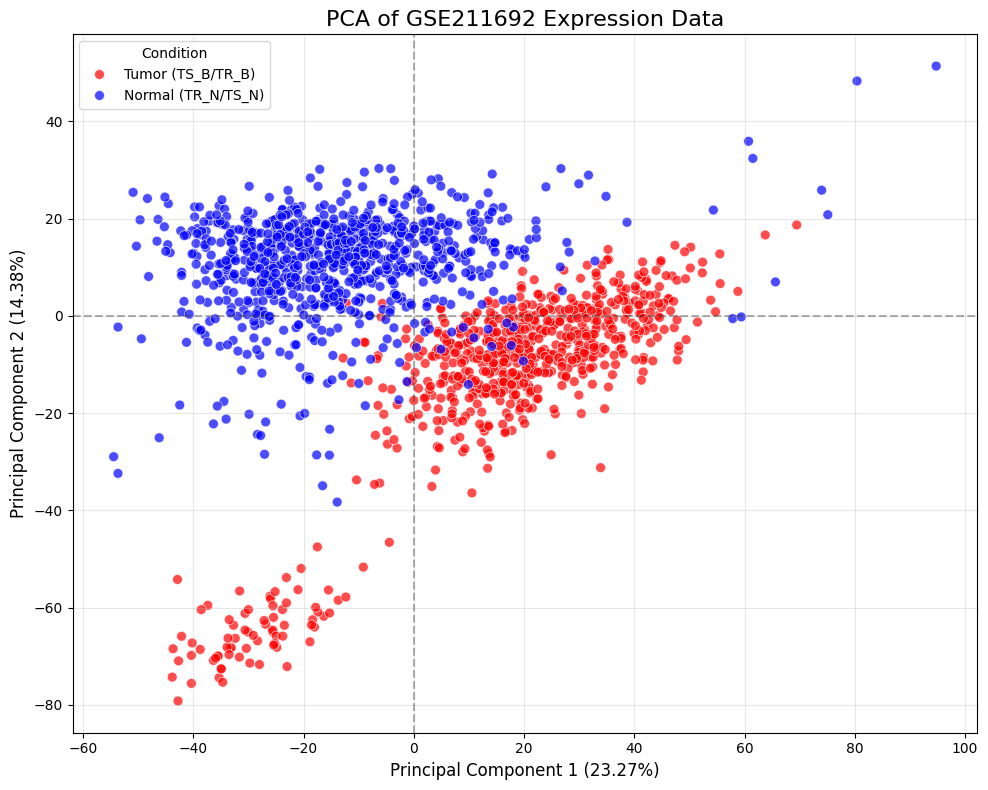

In [13]:
# =========================================================
# PCA and Visualization
# =========================================================
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("Performing PCA...")

# 1. Separate features (expression data) and target labels
X = df.drop(columns=['type'])
y = df['type']

# 2. Standardize the data (mean=0, variance=1)
# PCA is highly sensitive to the scale of the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Perform PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Get the explained variance percentage for the axes
explained_variance = pca.explained_variance_ratio_ * 100

# 4. Create a DataFrame for visualization
# Ensure indices match the original dataframe
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'], index=df.index)
pca_df['type'] = y.values

# Map numeric types back to string labels for the plot legend.
# Adjust the strings below if you want shorter or more specific names
pca_df['Disease Type'] = pca_df['type'].map({
    0: 'Normal (TR_N/TS_N)',
    1: 'Tumor (TS_B/TR_B)'
})

# 5. Visualize with Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Disease Type',
    palette={'Normal (TR_N/TS_N)': 'blue', 'Tumor (TS_B/TR_B)': 'red'},
    data=pca_df,
    alpha=0.7,
    s=50
)

# Formatting the plot
# Using locals().get() as a safeguard in case GEO_ID isn't defined in this cell
current_geo_id = locals().get('GEO_ID', 'GSE211692')
plt.title(f'PCA of {current_geo_id} Expression Data', fontsize=16)
plt.xlabel(f'Principal Component 1 ({explained_variance[0]:.2f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({explained_variance[1]:.2f}%)', fontsize=12)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.3)
plt.legend(title='Condition')
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the plot
# Safeguard: define output_dir if missing and create the folder if it doesn't exist
current_out_dir = locals().get('output_dir', './output')
os.makedirs(current_out_dir, exist_ok=True)

pca_plot_path = os.path.join(current_out_dir, f"{current_geo_id}_PCA_plot.png")
plt.savefig(pca_plot_path, dpi=300)
print(f"PCA plot saved to: {pca_plot_path}")

plt.show()